## Задание №13. 

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
url = "https://stroka.kg/kupit-kvartiru/"
tables = pd.read_html(url)
data = pd.concat(tables, ignore_index=True)
display(data.tail(50))

,0,1,2,3,4
314,NaN,NaN,NaN,NaN,NaN
315,56500$,1,ИНК,32м2,"АН 1ком.квар, Скрябина-Панфилова, инд, 4/5"
316,NaN,NaN,NaN,NaN,NaN
317,56500$,1,ХР,32м2,АН 56 500$ США!!! Срочно!!! Срочно!!! Срочно!!...
318,NaN,NaN,NaN,NaN,NaN
319,56500$,1,104,30м2,АН Срочно Продается
320,NaN,NaN,NaN,NaN,NaN
321,56500$,1,105,36м2,АН Срочно Продается
322,NaN,NaN,NaN,NaN,NaN
323,56500$,1,Э,42м2,АН Срочно Продается


In [ ]:
data.columns = ['Цена', 'Комнат', 'Серия', 'Площадь', 'Заголовок объявления']
data = data.dropna()
display(data.head(10))

,Цена,Комнат,Серия,Площадь,Заголовок объявления
0,65500.0,2,104,43,"Срочно!АН 2-х ком кв, 104 серии, 1/5, Боконбае..."
1,85000.0,2,СТ,44,"Срочно!АН 2-х ком. кв, 43,5 кв.м., 2/3, сталин..."
2,129000.0,3,Э,98,"Срочно!АН 3-х ком элитка, 98 кв.м., 9/10, Маги..."
3,105000.0,3,106У,86,"Срочно!АН 3-х ком. кв. серия 106 (улучшенная, ..."
4,218000.0,3,Э,122,"Срочно!АН 3-х ком кв, премиум класса в ЖК Roya..."
5,135000.0,3,ИН,92,"Срочно!АН 3-х ком.кв., инд, (2+1), 92 кв.м., 4..."
22,18500.0,1,ГТ,12,АН 18 500$ США!!! Срочно!!! Продаю 1кв. гост.т...
23,20500.0,1,ГТ,12,АН Продаю комнату ГТ
24,23500.0,1,ИНК,18,АН 1кв квартира мкр Сейтек ул.Южная Магистраль
25,23500.0,1,ИН,18,АН Продаю комнату 18 м2 с санузлом ЖК Сары Челек


In [ ]:
data['Цена'] = data['Цена'].astype(str)

data = data[data['Цена'].str.contains(r'\d', na=False)]

data['Цена'] = data['Цена'].str.replace('$', '', regex=False)\
                                       .str.replace(',', '', regex=False)\
                                       .str.strip()

data['Цена'] = pd.to_numeric(data['Цена'], errors='coerce')

data = data.dropna(subset=['Цена'])

data['Площадь'] = data['Площадь'].astype(str).str.replace('м2', '', regex=False)
data['Площадь'] = pd.to_numeric(data['Площадь'], errors='coerce')
data['Комнат'] = pd.to_numeric(data['Комнат'], errors='coerce')
data.reset_index(drop=True, inplace=True)
data.head()

,Цена,Комнат,Серия,Площадь,Заголовок объявления
0,65500.0,2,104,43,"Срочно!АН 2-х ком кв, 104 серии, 1/5, Боконбае..."
1,85000.0,2,СТ,44,"Срочно!АН 2-х ком. кв, 43,5 кв.м., 2/3, сталин..."
2,129000.0,3,Э,98,"Срочно!АН 3-х ком элитка, 98 кв.м., 9/10, Маги..."
3,105000.0,3,106У,86,"Срочно!АН 3-х ком. кв. серия 106 (улучшенная, ..."
4,218000.0,3,Э,122,"Срочно!АН 3-х ком кв, премиум класса в ЖК Roya..."


In [ ]:
# Фильтрация по цене
data = data[data['Цена'] >= 15000]

# Удалим последнюю строку, если есть хотя бы одна
if not data.empty:
    data = data.drop(data.index[-1])

# Посмотрим на результат
display(data.head(10))

,Цена,Комнат,Серия,Площадь,Заголовок объявления
0,65500.0,2,104,43,"Срочно!АН 2-х ком кв, 104 серии, 1/5, Боконбае..."
1,85000.0,2,СТ,44,"Срочно!АН 2-х ком. кв, 43,5 кв.м., 2/3, сталин..."
2,129000.0,3,Э,98,"Срочно!АН 3-х ком элитка, 98 кв.м., 9/10, Маги..."
3,105000.0,3,106У,86,"Срочно!АН 3-х ком. кв. серия 106 (улучшенная, ..."
4,218000.0,3,Э,122,"Срочно!АН 3-х ком кв, премиум класса в ЖК Roya..."
5,135000.0,3,ИН,92,"Срочно!АН 3-х ком.кв., инд, (2+1), 92 кв.м., 4..."
22,18500.0,1,ГТ,12,АН 18 500$ США!!! Срочно!!! Продаю 1кв. гост.т...
23,20500.0,1,ГТ,12,АН Продаю комнату ГТ
24,23500.0,1,ИНК,18,АН 1кв квартира мкр Сейтек ул.Южная Магистраль
25,23500.0,1,ИН,18,АН Продаю комнату 18 м2 с санузлом ЖК Сары Челек


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 144 entries, 0 to 159
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Цена                  144 non-null    float64
 1   Комнат                144 non-null    int64  
 2   Серия                 144 non-null    object 
 3   Площадь               144 non-null    int64  
 4   Заголовок объявления  144 non-null    object 
dtypes: float64(1), int64(2), object(2)
memory usage: 6.8+ KB


In [ ]:
data.describe()

,Цена,Комнат,Площадь
count,144.000000,144.000000,144.000000
mean,51785.291667,1.256944,37.666667
std,20326.667518,0.564033,15.284253
min,18500.000000,1.000000,12.000000
25%,46375.000000,1.000000,30.000000
50%,53000.000000,1.000000,34.000000
75%,55735.000000,1.000000,43.000000
max,218000.000000,4.000000,122.000000


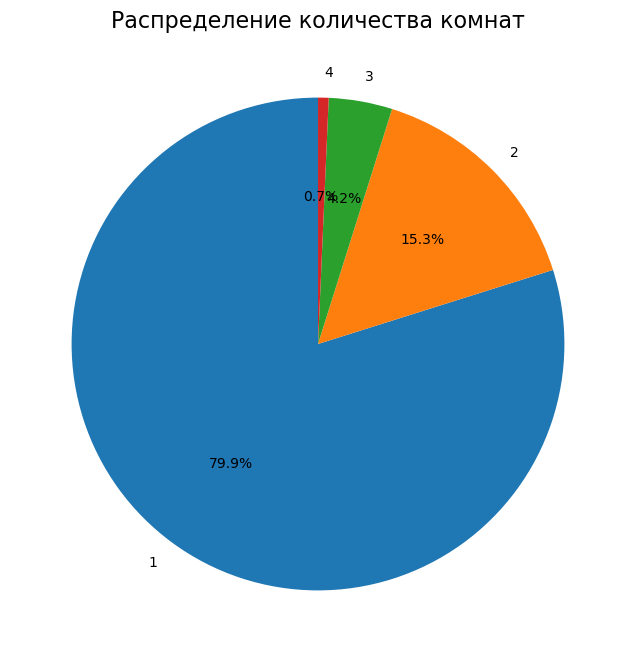

In [ ]:
room_counts = data['Комнат'].value_counts()
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']  # Разные цвета

plt.figure(figsize=(8, 8))
plt.pie(
    room_counts, 
    labels=room_counts.index, 
    autopct='%1.1f%%', 
    startangle=90, 
    colors=colors
)
plt.title('Распределение количества комнат', fontsize=16)
plt.show()


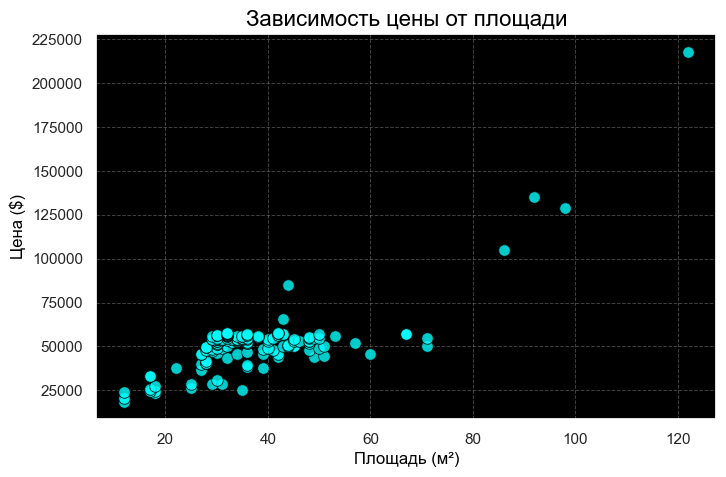

In [ ]:
sns.set_theme(style="darkgrid", palette="deep")
plt.figure(figsize=(8, 5))
sns.scatterplot(data=data, x='Площадь', y='Цена', color='cyan', edgecolor='black', s=70, alpha=0.8)
plt.title("Зависимость цены от площади", fontsize=16, color='black')
plt.xlabel('Площадь (м²)', fontsize=12, color='black')
plt.ylabel('Цена ($)', fontsize=12, color='black')
plt.gca().set_facecolor('black')
plt.grid(color='gray', linestyle='--', linewidth=0.7, alpha=0.5)
plt.show()

In [ ]:
X = data[['Комнат', 'Площадь']]
y = data['Цена']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Среднеквадратичная ошибка (MSE): {mse}")
print(f"Коэффициент детерминации (R²): {r2}")

Среднеквадратичная ошибка (MSE): 421665419.3629995
Коэффициент детерминации (R²): 0.6113204383420693


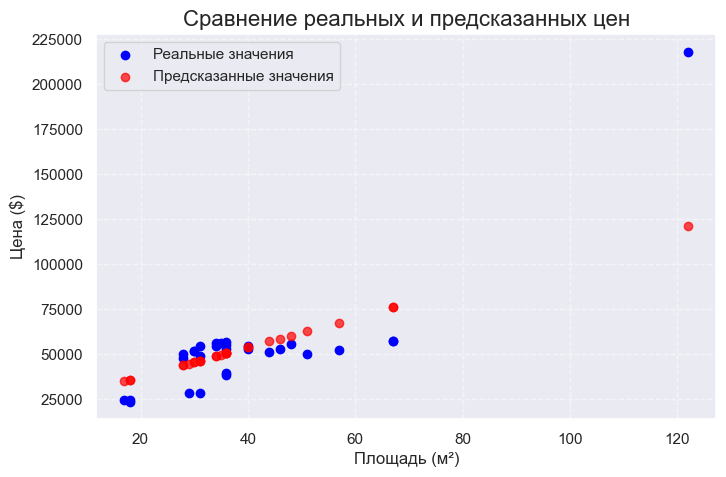

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(X_test['Площадь'], y_test, color='blue', label='Реальные значения')  # Реальные значения
plt.scatter(X_test['Площадь'], y_pred, color='red', label='Предсказанные значения', alpha=0.7)  # Предсказания
plt.title("Сравнение реальных и предсказанных цен", fontsize=16)
plt.xlabel("Площадь (м²)", fontsize=12)
plt.ylabel("Цена ($)", fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
new_cases = pd.DataFrame({
    'Комнат': [1, 2, 3, 2, 1, 3, 4, 2, 3, 1],
    'Площадь': [35, 50, 80, 60, 40, 100, 120, 45, 95, 30]
})
predicted_prices = model.predict(new_cases)
new_cases['Предсказанная цена'] = predicted_prices
display(new_cases)

,Комнат,Площадь,Предсказанная цена
0,1,35,49615.657352
1,2,50,62137.198487
2,3,80,86865.926831
3,2,60,70275.323293
4,1,40,53684.719756
5,3,100,103142.176443
6,4,120,119732.779981
7,2,45,58068.136084
8,3,95,99073.114040
9,1,30,45546.594949


In [ ]:
try:
    rooms = int(input("Введите количество комнат: "))
    area = float(input("Введите площадь квартиры (м²): "))
    user_data = pd.DataFrame({'Комнат': [rooms], 'Площадь': [area]})
    predicted_price = model.predict(user_data)[0]
    print(f"Предсказанная цена квартиры: ${predicted_price:.2f}")
except ValueError:
    print("Ошибка: введите корректные числовые значения для количества комнат и площади.")

Введите количество комнат:  2
Введите площадь квартиры (м²):  60


Предсказанная цена квартиры: $70275.32


## **Заключение**

1) Парсинг данных: Это процесс извлечения структурированных данных из веб-страниц или файлов для анализа или обработки, например, с использованием библиотек BeautifulSoup, pandas, selenium.

2) Машинное обучение: Это область науки, связанная с созданием алгоритмов, которые позволяют компьютерам обучаться на данных для выполнения задач. Цели: прогнозирование, классификация, кластеризация и оптимизация.

3) Популярные библиотеки:

scikit-learn (классическое машинное обучение)

TensorFlow и PyTorch (глубокое обучение)

pandas и NumPy (обработка данных)

XGBoost, LightGBM (градиентный бустинг).

4) Виды машинного обучения:

Обучение с учителем (регрессия, классификация)

Обучение без учителя (кластеризация, понижение размерности)

Обучение с подкреплением.

5) Линейная регрессия: Метод нахождения зависимости между переменными. Пример: прогноз цены квартиры по площади.

6) Логистическая регрессия: Метод классификации, применяемый для прогнозирования вероятностей событий. Пример: предсказание болезни на основе медицинских данных.
